# LABS-12: Value
Arnav Khanna | DS1001 - Professor Wright | November 20, 2026

This notebook recreates the supplied movie classifier and evaluates its predictions by country, genre, and language. The supplied cleaned dataset contains 10,052 movies. High score is the positive outcome (1).

**Method note:** A previous movie-model k value was not available. Rather than claim a LABS-9 result, this notebook selects k from 3, 5, 7, 9, 11, 15, 21, and 31 using five-fold stratified cross-validation within the training split only. The supplied 80/20 split and random seed 45 are unchanged. The test split is used only after selection. Existing numeric scaling is retained to match the supplied cleaned data; its original fitting procedure is unknown.

Fairlearn references: [metric definitions](https://fairlearn.org/v0.10/api_reference/index.html#module-fairlearn.metrics), [demographic parity ratio](https://fairlearn.org/v0.10/api_reference/generated/fairlearn.metrics.demographic_parity_ratio.html), and [equalized odds ratio](https://fairlearn.org/v0.10/api_reference/generated/fairlearn.metrics.equalized_odds_ratio.html).


This notebook was executed in GitHub Codespaces using ArnavKhanna_env. All 22 code cells completed without errors, and the model results match the accompanying report. Execution details are saved in the notebook metadata and codespace_execution.json.

In [1]:
# Uncomment to install in the active notebook kernel.
# %pip install fairlearn==0.10.0 pandas scikit-learn matplotlib


In [2]:
from pathlib import Path
import json
from functools import partial
import pandas as pd
import numpy as np
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
import fairlearn
import fairlearn.metrics
from fairlearn.metrics import MetricFrame, count, true_positive_rate, false_positive_rate, selection_rate
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 150)
print('Fairlearn version:', fairlearn.__version__)

import sys
print("Python executable:", sys.executable)


Fairlearn version: 0.10.0
Python executable: /workspaces/DS1001-LABS-Projects/ArnavKhanna_env/bin/python


## Recreate the model
First you will rebuild the model that you made in LABS-9: Analytics.

### Read in the data
The data you are reading in is the **cleaned** data that you created in LABS-9. Upload it to folders in collab if your using it.

In [3]:
model_data = pd.read_csv('imdb_movies_cleaned.csv')
required = {'score', 'country', 'top_genre', 'top_lang'}
assert required.issubset(model_data.columns)
assert not model_data.isna().any().any(), 'Inspect missing values before modeling.'
assert set(model_data['score'].unique()) == {'low', 'high'}, 'Unexpected score labels.'
print('Dataset shape:', model_data.shape)
display(model_data.head())


Dataset shape: (10052, 7)


,score,budget_x,revenue,country,top_genre,top_lang,year
0,high,0.163043,0.092901,AU,Drama,English,1.000000
1,high,1.000000,0.792417,AU,Science Fiction,English,0.991667
2,high,0.217391,0.247788,AU,Animation,English,1.000000
3,high,0.026739,0.011697,AU,Animation,Spanish,1.000000
4,low,0.167391,0.116613,US,Action,English,1.000000


Use 0 for low scores and 1 for high scores so the positive outcome is explicit and consistent. Some Fairlearn functions accept other labels through `pos_label`; 0/1 is the convention used by this lab, not a universal requirement of every Fairlearn metric.


In [4]:
# Recode 'score' as 0 (low) or 1 (high)
model_data['score'] = model_data['score'].map({'low': 0, 'high': 1})

### Seperate features from target

In [5]:
# features: all columns except 'score'
features = model_data.drop('score', axis=1)

# Target: score column
target = model_data['score']

### Dummy variables

In [6]:
## create dummy variables for the features dataframe
features = pd.get_dummies(features)

# preview the new features dataframe
features.head()

,budget_x,revenue,year,country_AU,country_ES,country_FR,country_GB,country_HK,country_IT,country_JP,...,top_lang_ Norwegian,top_lang_ Polish,top_lang_ Portuguese,top_lang_ Russian,top_lang_ Spanish,top_lang_ Swedish,top_lang_ Tagalog,top_lang_ Thai,top_lang_ Turkish,top_lang_other
0,0.163043,0.092901,1.000000,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,1.000000,0.792417,0.991667,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,0.217391,0.247788,1.000000,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,0.026739,0.011697,1.000000,True,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
4,0.167391,0.116613,1.000000,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


### Train/Test split

In [7]:
# train test split
features_train, features_test, target_train, target_test = train_test_split(features, target, test_size=0.2, random_state=45)


### Select, train, test, and evaluate the model
No previous movie-model k was supplied. Select it on training data only, maximizing mean cross-validation accuracy. If scores tie, choose the smallest candidate. Keep the held-out test data untouched until final evaluation.


In [8]:
candidate_k = [3, 5, 7, 9, 11, 15, 21, 31]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=45)
cv_rows = []
for k in candidate_k:
    scores = cross_val_score(KNeighborsClassifier(n_neighbors=k), features_train, target_train, cv=cv, scoring='accuracy')
    cv_rows.append({'k': k, 'mean_cv_accuracy': scores.mean(), 'sd_cv_accuracy': scores.std()})
cv_results = pd.DataFrame(cv_rows)
best_k = int(cv_results.sort_values(['mean_cv_accuracy', 'k'], ascending=[False, True]).iloc[0]['k'])
display(cv_results)
print('Selected k:', best_k)
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(features_train, target_train)
target_predicted = knn.predict(features_test)
print('Training rows:', len(target_train), '| Test rows:', len(target_test))
print('Test accuracy:', accuracy_score(target_test, target_predicted))


,k,mean_cv_accuracy,sd_cv_accuracy
0,3,0.662728,0.013034
1,5,0.671558,0.010157
2,7,0.679143,0.009771
3,9,0.685114,0.011455
4,11,0.687104,0.011389
5,15,0.690461,0.008461
6,21,0.684368,0.010278
7,31,0.683124,0.005161


Selected k: 15
Training rows: 8041 | Test rows: 2011
Test accuracy: 0.7066136250621581


In [9]:
## Print out the data to use below
model_data.head()

,score,budget_x,revenue,country,top_genre,top_lang,year
0,1,0.163043,0.092901,AU,Drama,English,1.000000
1,1,1.000000,0.792417,AU,Science Fiction,English,0.991667
2,1,0.217391,0.247788,AU,Animation,English,1.000000
3,1,0.026739,0.011697,AU,Animation,Spanish,1.000000
4,0,0.167391,0.116613,US,Action,English,1.000000


## Representation in all three categories
These counts describe the full cleaned dataset, not just the test split. A larger class is more represented; this alone does not establish better predictions or unfair treatment.



Category: country


,count,percent
country,,
AU,4880,48.547553
US,2716,27.019499
other,709,7.053323
JP,502,4.994031
KR,358,3.561480
FR,219,2.178671
GB,172,1.711102
ES,151,1.502189
IT,123,1.223637



Category: top_genre


,count,percent
top_genre,,
Drama,1865,18.553522
Action,1563,15.549144
Comedy,1377,13.698766
Horror,931,9.261838
Animation,885,8.804218
Thriller,577,5.740151
Adventure,571,5.680462
Romance,413,4.108635
Crime,371,3.690808



Category: top_lang


,count,percent
top_lang,,
English,7381,73.428173
Japanese,675,6.715082
Spanish,388,3.859928
Korean,384,3.820135
French,282,2.805412
Chinese,144,1.432551
Italian,142,1.412654
Cantonese,141,1.402706
German,89,0.885396


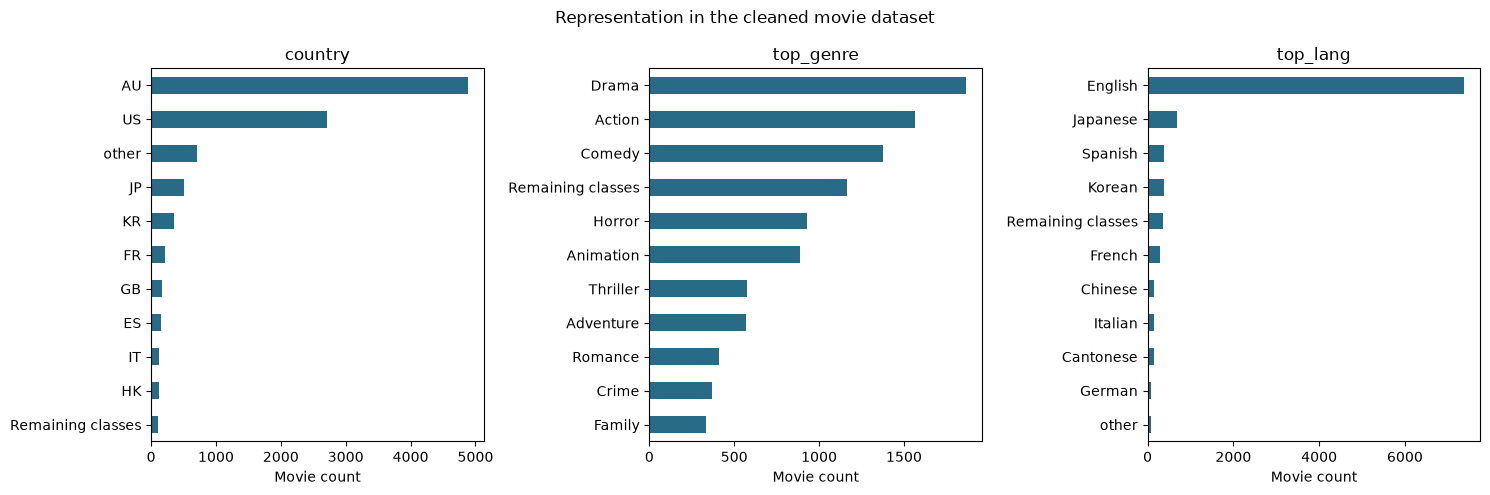

In [10]:
representation = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, category in zip(axes, ['country', 'top_genre', 'top_lang']):
    counts = model_data[category].value_counts()
    table = counts.rename('count').to_frame()
    table['percent'] = 100 * table['count'] / len(model_data)
    representation[category] = table
    print('\nCategory:', category)
    display(table)
    # Display the ten largest classes and aggregate smaller ones for legibility.
    shown = counts.iloc[:10].copy()
    if len(counts) > 10:
        shown.loc['Remaining classes'] = counts.iloc[10:].sum()
    shown.index = shown.index.astype(str).str.strip()
    shown.sort_values().plot.barh(ax=ax, color='#286b87')
    ax.set(title=category, xlabel='Movie count', ylabel='')
fig.suptitle('Representation in the cleaned movie dataset')
fig.tight_layout()
fig.savefig('class_representation.png', dpi=200, bbox_inches='tight')
plt.show()


## Fairness Metrics

We are using the Fairlearn package in Python.

You will need to understand what the metrics used below mean and how they are calculated. You can find information on the functions used in their documentation: https://fairlearn.org/v0.10/api_reference/index.html#module-fairlearn.metrics

In [11]:
# Explicit positive labels avoid ambiguity within small subgroups.
my_metrics = {
    'true positive rate': partial(true_positive_rate, pos_label=1),
    'false positive rate': partial(false_positive_rate, pos_label=1),
    'selection rate': selection_rate,
    'count': count,
}
def indicator(category, value):
    # Trim labels for comparison; preserve the original model feature encoding.
    return model_data.loc[features_test.index, category].astype(str).str.strip().eq(value).astype(int)

groups = {'country': indicator('country', 'AU'),
          'top_lang': indicator('top_lang', 'English'),
          'top_genre': indicator('top_genre', 'Drama')}
frames = {category: MetricFrame(metrics=my_metrics, y_true=target_test,
          y_pred=target_predicted, sensitive_features=group)
          for category, group in groups.items()}
mf_country, mf_lang, mf_genre = frames['country'], frames['top_lang'], frames['top_genre']
print('Group 1: AU / English / Drama respectively. Group 0: all other values in that category.')


Group 1: AU / English / Drama respectively. Group 0: all other values in that category.


In [12]:
def create_confmatrix(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return pd.DataFrame({'predicted positive': [tp, fp], 'predicted negative': [fn, tn]},
                        index=['actual positive', 'actual negative'])


### Overall metrics

Here is the confusion matrix for the model overall with *counts* for the true positive, false positive, true negative, and false negative.

For more information on confusion matrices, check out the wiki page: https://en.wikipedia.org/wiki/Confusion_matrix

> Use this information to answer **question 3**.

In [13]:
# overall confusion matrix
print("Confusion matrix for all test data:")
create_confmatrix(target_test, target_predicted)

Confusion matrix for all test data:


,predicted positive,predicted negative
actual positive,689,299
actual negative,291,732


In [14]:
## The overall metrics. You'll use these to compare to with the metrics broken down by each category below.
## Think about how the differing performance would impact that group based on your understanding of each metric.
pd.DataFrame(mf_country.overall, columns = ["overall"]).T

,true positive rate,false positive rate,selection rate,count
overall,0.697368,0.284457,0.48732,2011.0


### Metrics by category

Here we are comparing the most prevalent class in each category to the rest of the categories.

> Use this information to answer **questions 4 & 5**.

#### `country`

The most prevalent country value is "AU". We will compare the model performance for the most prevalent country to the performance on the rest of the countries.

In [15]:
## metrics broken down by country classes. Compare these to the metrics above.
mf_country.by_group

,true positive rate,false positive rate,selection rate,count
country,,,,
0,0.633867,0.222997,0.400593,1011.0
1,0.747731,0.363029,0.575000,1000.0


In [16]:
print('Demographic parity ratio:', fairlearn.metrics.demographic_parity_ratio(target_test, target_predicted, sensitive_features=groups['country']))
print('Equalized odds ratio:', fairlearn.metrics.equalized_odds_ratio(target_test, target_predicted, sensitive_features=groups['country']))


Demographic parity ratio: 0.6966842988001549
Equalized odds ratio: 0.614266475705949


#### `top_lang`


The most prevalent language value is "English". We will compare the model performance for the most prevalent language to the performance on the rest of the languages.

In [17]:
## metrics broken down by top_lang classes. Compare these to the metrics above.

mf_lang.by_group

,true positive rate,false positive rate,selection rate,count
top_lang,,,,
0,0.745763,0.352941,0.570356,533.0
1,0.676768,0.263694,0.457375,1478.0


In [18]:
print('Demographic parity ratio:', fairlearn.metrics.demographic_parity_ratio(target_test, target_predicted, sensitive_features=groups['top_lang']))
print('Equalized odds ratio:', fairlearn.metrics.equalized_odds_ratio(target_test, target_predicted, sensitive_features=groups['top_lang']))


Demographic parity ratio: 0.8019104764617905
Equalized odds ratio: 0.7471337579617834


#### `top_genre`


The most prevalent genre value is "Drama". We will compare the model performance for the most prevalent genre to the performance on the rest of the genres.

In [19]:
## metrics broken down by top_genre classes. Compare these to the metrics above.

mf_genre.by_group

,true positive rate,false positive rate,selection rate,count
top_genre,,,,
0,0.653226,0.248322,0.432234,1638.0
1,0.831967,0.534884,0.729223,373.0


In [20]:
print('Demographic parity ratio:', fairlearn.metrics.demographic_parity_ratio(target_test, target_predicted, sensitive_features=groups['top_genre']))
print('Equalized odds ratio:', fairlearn.metrics.equalized_odds_ratio(target_test, target_predicted, sensitive_features=groups['top_genre']))


Demographic parity ratio: 0.5927332471450119


Equalized odds ratio: 0.46425444995623


## Check denominators, compare groups, and export results
TPR uses actual high-scoring movies as its denominator. FPR uses actual low-scoring movies. A missing outcome class makes the corresponding rate undefined; do not treat an API's fallback value as evidence of fairness. The table below exposes these denominators. Comparisons are descriptive estimates from one held-out split.

AU-versus-rest, English-versus-rest, and Drama-versus-rest comparisons may conceal disparities among individual countries, languages, genres, or their intersections.


In [21]:
details = []
ratios = {}
for category, group in groups.items():
    for value in [0, 1]:
        mask = group.to_numpy() == value
        tn, fp, fn, tp = confusion_matrix(target_test.to_numpy()[mask], target_predicted[mask], labels=[0, 1]).ravel()
        details.append({'category': category, 'group': value, 'n': int(mask.sum()),
                        'TP': int(tp), 'FN': int(fn), 'FP': int(fp), 'TN': int(tn),
                        'TPR': tp/(tp+fn) if tp+fn else np.nan,
                        'FPR': fp/(fp+tn) if fp+tn else np.nan,
                        'selection_rate': (tp+fp)/mask.sum() if mask.sum() else np.nan})
    ratios[category] = {
        'DPR': float(fairlearn.metrics.demographic_parity_ratio(target_test, target_predicted, sensitive_features=group)),
        'EOR': float(fairlearn.metrics.equalized_odds_ratio(target_test, target_predicted, sensitive_features=group))}
group_results = pd.DataFrame(details)
assert (group_results[['TP', 'FN']].sum(axis=1) > 0).all()
assert (group_results[['FP', 'TN']].sum(axis=1) > 0).all()
display(group_results)
display(pd.DataFrame(ratios).T)
for category, frame in frames.items():
    observed = group_results[group_results.category == category].set_index('group')
    np.testing.assert_allclose(observed[['TPR','FPR','selection_rate']].to_numpy(),
                               frame.by_group[['true positive rate','false positive rate','selection rate']].to_numpy())
    for metric, column in [('true positive rate','TPR'), ('false positive rate','FPR'), ('selection rate','selection_rate')]:
        display((frame.by_group[metric] - frame.overall[metric]).rename(f'{category}: {column} difference from overall'))
group_results.to_csv('group_metrics.csv', index=False)
pd.DataFrame(ratios).T.to_csv('fairness_ratios.csv')
cv_results.to_csv('k_selection.csv', index=False)
pd.DataFrame({'actual': target_test, 'predicted': target_predicted}).to_csv('test_predictions.csv', index_label='source_row')
overall = {k: float(v) for k, v in mf_country.overall.items()}
overall['accuracy'] = float(accuracy_score(target_test, target_predicted))
tn, fp, fn, tp = confusion_matrix(target_test, target_predicted, labels=[0,1]).ravel()
results = {'best_k': best_k, 'train_n': len(target_train), 'test_n': len(target_test),
           'overall': overall, 'confusion': {'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp)},
           'groups': details, 'ratios': ratios,
           'representation': {k: [{'class': str(idx).strip(), 'count': int(row['count']), 'percent': float(row['percent'])}
                                  for idx, row in table.iterrows()] for k,table in representation.items()}}
Path('analysis_results.json').write_text(json.dumps(results, indent=2))
print('Verified Fairlearn rates against the confusion-matrix counts. Saved reproducible result tables.')


,category,group,n,TP,FN,FP,TN,TPR,FPR,selection_rate
0,country,0,1011,277,160,128,446,0.633867,0.222997,0.400593
1,country,1,1000,412,139,163,286,0.747731,0.363029,0.575000
2,top_lang,0,533,220,75,84,154,0.745763,0.352941,0.570356
3,top_lang,1,1478,469,224,207,578,0.676768,0.263694,0.457375
4,top_genre,0,1638,486,258,222,672,0.653226,0.248322,0.432234
5,top_genre,1,373,203,41,69,60,0.831967,0.534884,0.729223


,DPR,EOR
country,0.696684,0.614266
top_lang,0.801910,0.747134
top_genre,0.592733,0.464254


country
0   -0.063501
1    0.050363
Name: country: TPR difference from overall, dtype: float64

country
0   -0.061461
1    0.078571
Name: country: FPR difference from overall, dtype: float64

country
0   -0.086726
1    0.087680
Name: country: selection_rate difference from overall, dtype: float64

top_lang
0    0.048394
1   -0.020601
Name: top_lang: TPR difference from overall, dtype: float64

... (2 outputs left out)

top_genre
0   -0.044143
1    0.134599
Name: top_genre: TPR difference from overall, dtype: float64

top_genre
0   -0.036135
1    0.250426
Name: top_genre: FPR difference from overall, dtype: float64

top_genre
0   -0.055085
1    0.241903
Name: top_genre: selection_rate difference from overall, dtype: float64

Verified Fairlearn rates against the confusion-matrix counts. Saved reproducible result tables.


## Question 7: Copilot exchange

The user supplied the actual exchange on November 20, 2026. The full prompt, clarification, follow-up, response, and verification appear in the written responses below and in copilot_exchange.json. The following cell independently checks the exact numerical example Copilot supplied. It is hypothetical, not measured movie data.

In [22]:
# Verify the exact hypothetical example in the supplied Copilot response.
import pandas as pd
import numpy as np
from IPython.display import display
from fairlearn.metrics import demographic_parity_ratio, equalized_odds_ratio
example = pd.DataFrame({'TP': [40,20], 'FN': [10,30], 'FP': [10,30], 'TN': [40,20]}, index=['A','B'])
example['TPR'] = example.TP / (example.TP + example.FN)
example['FPR'] = example.FP / (example.FP + example.TN)
example['selection_rate'] = (example.TP + example.FP) / 100
example['accuracy'] = (example.TP + example.TN) / 100
example_dpr = example.selection_rate.min() / example.selection_rate.max()
example_eor = min(example.TPR.min()/example.TPR.max(), example.FPR.min()/example.FPR.max())
y_true, y_pred, group_labels = [], [], []
for group, row in example.iterrows():
    for outcome, predicted, count in [(1,1,row.TP),(1,0,row.FN),(0,1,row.FP),(0,0,row.TN)]:
        y_true.extend([outcome]*int(count))
        y_pred.extend([predicted]*int(count))
        group_labels.extend([group]*int(count))
api_dpr = demographic_parity_ratio(y_true,y_pred,sensitive_features=group_labels)
api_eor = equalized_odds_ratio(y_true,y_pred,sensitive_features=group_labels)
assert np.isclose(example_dpr,1.0) and np.isclose(example_eor,1/3)
assert np.isclose(api_dpr,example_dpr) and np.isclose(api_eor,example_eor)
display(example)
print('Arithmetic DPR:',example_dpr,'| Fairlearn DPR:',api_dpr)
print('Arithmetic EOR:',example_eor,'| Fairlearn EOR:',api_eor)
print('Copilot example verified: equal selection, different error rates.')

,TP,FN,FP,TN,TPR,FPR,selection_rate,accuracy
A,40,10,10,40,0.8,0.2,0.5,0.8
B,20,30,30,20,0.4,0.6,0.5,0.4


Arithmetic DPR: 1.0 | Fairlearn DPR: 1.0
Arithmetic EOR: 0.33333333333333337 | Fairlearn EOR: 0.33333333333333337
Copilot example verified: equal selection, different error rates.


## Notes for repeating the analysis
- Place the cleaned CSV beside the notebook; use the intended kernel and install Fairlearn if missing.
- Inspect score labels, missing values, group spellings, and numeric scaling before modeling. The source CSV contains a leading space in language labels; the model keeps that encoding while group comparisons strip it.
- Reuse the supplied split seed (45) and test size (0.2). Select k on training folds only, then fit on the full training split and evaluate once on the held-out test split.
- Recompute representation counts and inspect subgroup denominators. Ratios do not indicate which group has the larger rate; read the per-group table as well.
- For future deployment, test separate and intersecting groups with uncertainty intervals. Audit whether cleaning/scaling used the full dataset, and whether revenue is available at the time predictions would guide advertising.
- A high-score label is not an award outcome. Evaluate awards and budget effects directly before using this model for that purpose.
- The report accompanies this notebook. The actual Copilot response is verified below. Codespaces execution details are recorded in the notebook metadata; use the repository history to check the GitHub save workflow.


## Written responses (same content as the accompanying report)

LABS-12: Value

Arnav Khanna | DS1001 - Professor Wright | November 20, 2026

Questions

**1. What the five metrics measure**

A positive prediction means a movie is predicted to earn a high score. TP means correctly predicted high; FP means actually low but predicted high; FN means actually high but predicted low; TN means correctly predicted low. N is the number of movies in the group being evaluated, and g stands for a group.

True positive rate (TPR) = TP / (TP + FN). This is the fraction of genuinely high-scoring movies the model identifies. Its range is 0 to 1: 1 means all are found and 0 means none are found. Higher TPR means fewer potentially promising movies are overlooked. Equal TPR across groups means equal detection rates, but a single TPR value does not establish fairness.

False positive rate (FPR) = FP / (FP + TN). This is the fraction of genuinely low-scoring movies incorrectly labeled high. Its range is 0 to 1: 0 means no false alarms and 1 means every low-scoring movie is labeled high. A higher FPR could direct advertising money toward more low-scoring movies. Equal FPR across groups means equal false-alarm rates; lower FPR alone does not prove fairness.

Selection rate (SR) = (TP + FP) / N. This is the fraction of all movies predicted high, whether correct or incorrect. Its range is 0 to 1: 0 selects none and 1 selects all. If positive predictions guide spending, SR describes how often a group could receive that opportunity. Equal selection rates represent demographic parity; neither endpoint is inherently fair or unfair.

Demographic parity ratio (DPR) = min(SRg) / max(SRg). Across the compared groups g, the ratio ranges from 0 to 1 when defined. A value of 1 means equal selection rates; 0 means one group is never selected while another is selected. Lower values indicate larger relative disparities in access to positive predictions, without accounting for actual scores.

Equalized odds ratio (EOR) = min[min(TPRg)/max(TPRg), min(FPRg)/max(FPRg)]. Its defined range is 0 to 1. A value of 1 means equal detection and false-alarm rates; 0 is an extreme relative disparity in at least one rate. Lower values indicate less equal error behavior. Equal rates can still describe a poor model. Rates or ratios with zero denominators require special care.

**2. Representation in country, top_genre, and top_lang**

| Category | Most prevalent class | All other classes |
| --- | --- | --- |
| country | AU: 4,880 (48.55%) | 5,172 (51.45%) |
| top_genre | Drama: 1,865 (18.55%) | 8,187 (81.45%) |
| top_lang | English: 7,381 (73.43%) | 2,671 (26.57%) |

None of the categories has equally represented classes. AU, Drama, and English have the largest individual class counts; only English exceeds all other classes combined. They are favored in representation, which does not by itself prove prediction bias. Small classes provide fewer examples to learn from and less stable evaluation estimates. Overall metrics can obscure their errors, so subgroup counts and rates must be examined together.

**3. Overall model performance**

For 2,011 test movies, TPR = 69.74%, FPR = 28.45%, and SR = 48.73%. Accuracy is 70.66%. The confusion counts are TP = 689, FN = 299, FP = 291, and TN = 732. High and low test counts are 988 and 1,023. The model uses k = 15, chosen by five-fold cross-validation within the 8,041 training movies, with the supplied 80/20 split and seed 45. This is a new k selection because no earlier movie-model k was supplied.

**4. Group performance and fairness ratios**

Each comparison uses the most prevalent individual class versus all other classes pooled together. Rates use test data; the representation counts in Question 2 use the full dataset.

| Group | Test n | TPR | FPR | SR |
| --- | --- | --- | --- | --- |
| AU | 1000 | 74.77% | 36.30% | 57.50% |
| Other countries | 1011 | 63.39% | 22.30% | 40.06% |
| English | 1478 | 67.68% | 26.37% | 45.74% |
| Other languages | 533 | 74.58% | 35.29% | 57.04% |
| Drama | 373 | 83.20% | 53.49% | 72.92% |
| Other genres | 1638 | 65.32% | 24.83% | 43.22% |

| Comparison | DPR | EOR |
| --- | --- | --- |
| AU vs. other countries | 0.697 | 0.614 |
| English vs. other languages | 0.802 | 0.747 |
| Drama vs. other genres | 0.593 | 0.464 |

Country. Compared with overall performance, AU has a TPR 5.04 percentage points higher, an FPR 7.86 points higher, and an SR 8.77 points higher. Other countries are 6.35, 6.15, and 8.67 points lower, respectively. The model finds more high-scoring AU movies, but also makes more false high predictions for AU. DPR = 0.697 means the other-country selection rate is about 69.7% of AU's. EOR = 0.614 is driven by the FPR gap: other countries have about 61.4% of AU's false-alarm rate. These ratios show unequal selection and error rates.

Language. English is below overall TPR, FPR, and SR by 2.06, 2.08, and 2.99 percentage points. Other languages are above overall by 4.84, 6.85, and 8.30 points. English movies receive fewer positive predictions and have fewer false alarms, but the model also misses a larger share of their actually high-scoring movies. DPR = 0.802 means English's selection rate is about 80.2% of the other-language rate. EOR = 0.747 reflects English's lower FPR relative to other languages. This comparison is closer to parity than the other two, but is still unequal.

Genre. Drama is above overall TPR, FPR, and SR by 13.46, 25.04, and 24.19 percentage points. Other genres are below by 4.41, 3.61, and 5.51 points. High-scoring dramas are found more often, but 53.49% of low-scoring dramas are also labeled high, compared with 24.83% for other genres. DPR = 0.593 means other genres are selected at about 59.3% of Drama's rate. EOR = 0.464 is driven by the FPR difference. Genre has the largest observed disparity in both ratios.

**5. Does the model perform fairly for all movie types?**

I do not think we can call the model fair across all movie types. The selection and error rates differ in all three comparisons, especially for genre. English is the most common language, but the model selects English movies less often and misses more of the ones that actually have high scores. The gaps show where performance differs, although they do not explain why. Actual score distributions differ between groups, and results from one test split may change with a different sample. Combining many classes into an "other" group can also hide problems within that group. We would need to check individual classes and combinations, such as language within genre, before making a claim about every movie type.

**6. Recommendation to the studio head**

I would not rely on this model to allocate advertising budgets across movie types or award categories. It finds about 70 of every 100 genuinely high-scoring films overall, so it misses about 30. Its false-alarm rate is much higher for dramas than other genres (53.49% versus 24.83%), which could skew spending. Other genres are recommended at about 59% of the rate for dramas (DPR = 0.593). Their false-alarm rate is about 46% of the drama rate (EOR = 0.464), so the model makes these mistakes much more often for dramas. The model predicts a high score, not an award win, and this dataset contains no award outcome to validate that claim. Revenue is also an input; verify it is available when advertising decisions are made. I would use it to explore patterns for now and check individual groups and actual award outcomes before using it to decide budgets.

**7. Copilot question, response, and verification**

Prompt: For a binary movie-score classifier, can demographic parity ratio equal 1 while equalized odds ratio is below 1? Give a two-group confusion-matrix example, calculate both ratios using Fairlearn’s default between-groups definitions, and explain what this means for allocating movie advertising budgets.

Copilot clarification: Hello Data Science Student! Before I work through the example, what have you tried so far, or what part of Fairlearn’s default ratio definitions is confusing?

My follow-up: i get they compare different rates but how can selection be equal and the errors be different? can u show a small example

Copilot response (as pasted): Hello Data Science Student! Yes. Selection rate is the share predicted positive; true-positive rate (TPR) is the share of actual positives correctly identified; false-positive rate (FPR) is the share of actual negatives incorrectly labeled positive.

Suppose “positive” means the classifier recommends advertising a movie. Each cell below is a movie count, with rows as actual outcome and columns as predicted outcome:

| Group | Actual success, predicted yes | Actual success, predicted no | Actual not success, predicted yes | Actual not success, predicted no |
| --- | --- | --- | --- | --- |
| A | 40 | 10 | 10 | 40 |
| B | 20 | 30 | 30 | 20 |

Both groups have 50 predicted “yes” out of 100, so their selection rates are each 0.5. Fairlearn’s default between-groups demographic parity ratio—the smaller selection rate divided by the larger—is therefore 0.5 / 0.5 = 1.

But their error rates differ: Group A has TPR 40/50 = 0.8 and FPR 10/50 = 0.2; Group B has TPR 20/50 = 0.4 and FPR 30/50 = 0.6. Fairlearn’s default between-groups equalized odds ratio takes the worse of the TPR and FPR ratios: min(0.4/0.8, 0.2/0.6) = min(0.5, 0.33) ≈ 0.33.

So both groups get the same share of movies recommended for ads, but the recommendations are less accurate for Group B: with the same spend per recommended movie, more ads go to movies that don’t succeed, and more successful movies are missed. Equal selection rates alone don’t guarantee equally effective budget allocation.

Verification: I can verify the formulas and arithmetic. Both groups have 50 predicted positives out of 100, so DPR = 1. Their TPR ratio is 0.4/0.8 = 0.5, and their FPR ratio is 0.2/0.6 = 1/3; EOR is therefore 1/3, or about 0.33. The notebook independently recreates these counts and checks the Fairlearn outputs against this arithmetic. The mathematical explanation is correct. In this lab, however, the target is a high movie score, so its references to "success" should mean high scores, not proven award wins or advertising returns. The budget interpretation assumes the same spending per selected movie; the example does not establish actual budget effects.

Takeaway

Check the groups – The model had about 71% accuracy overall, but that number left out the big difference in false alarms between dramas and other genres. Looking at each group helped me see why accuracy alone would be a weak reason to recommend the model. I also learned that being the largest class does not mean the model will predict that class better, since English movies had a lower true positive rate than other languages. In DS1001, we study how bias and error can enter a project, and this lab gave me a way to check those problems in the predictions. For future projects, I want to compare the errors across groups and check that the outcome I am predicting fits the decision someone wants to make.

Notes

Codespaces setup: Upload the completed notebook and CSV to your DS1001 Codespace. Activate the virtual environment from LABS-04 in the terminal, using source ArnavKhanna_env/bin/activate. In the notebook kernel selector, choose the same environment. Run pip install fairlearn, then pip freeze > requirements.txt in the terminal. The requirements file records the course environment used to run this notebook.

Keep the CSV in the same folder as the notebook, select the right Python environment, install the packages in requirements.txt, and run the cells in order. Confirm low = 0 and high = 1; inspect missing values and label spellings. The CSV uses a leading space in language labels, so group comparisons strip it while the model encoding is retained. Keep the supplied split fixed and choose k on training folds only. The source data already has scaled numeric columns; how those scales were fitted is unknown. Check that preprocessing and prediction-time features do not leak information.

Check TP, FN, FP, TN and the number of actual high and low scores in each group before interpreting the rates. Use counts from the full dataset for representation and held-out predictions for evaluation. Read the group table to determine direction: a ratio alone does not identify the group with the larger rate. Before a final project, add individual and intersecting group checks and uncertainty estimates. GitHub save steps: save the notebook, use git status to check the changed files, then git add the notebook, CSV if needed, and requirements.txt. Commit them with a short message and run git push. Check the repository on GitHub to confirm the latest notebook outputs and requirements are visible. Use the course environment for execution and check that the notebook and requirements appear on GitHub after pushing.